In [1]:
import sys
print(sys.executable)

C:\Users\jugal\langchain-env\Scripts\python.exe


In [3]:
# Importing necessary libraries
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_openai import ChatOpenAI
from langchain.agents.middleware import HumanInTheLoopMiddleware

from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, AnyMessage

from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.checkpoint.memory import MemorySaver


from dotenv import load_dotenv

# importing tools related libs
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.types import Command, interrupt

# For GoogleSerperAPI
from langchain_community.utilities import GoogleSerperAPIWrapper

import requests
import os
from langsmith import traceable

In [8]:
load_dotenv(".env.chatbot")

True

In [9]:
os.environ['LANGSMITH_PROJECT'] = 'HITL_With_Node'

In [10]:
# Defining model
model = ChatOpenAI(model = 'gpt-3.5-turbo')

In [11]:
# Creating tools

# Google Search tool

@tool
@traceable
def google_search(query:str)->any:
    '''This function takes a query and searches on Google Search Engine'''

    response = GoogleSerperAPIWrapper(type = 'search')

    return response.json()

# ============================== Weather Search ==============================

@tool
@traceable
def weather_search(city: str)->str:
    '''
    This function returns the live whether data of any city in the world.
    Pass any city name and it will return all the whether details.
    '''

    api_key = '6018a20db02a3eb6aa1ef7bffa662350'

    url = f"http://api.weatherstack.com/current?access_key={api_key}&query={city}"

    response = requests.get(url)

    return response.json()

# ============================== Train Details Search ==============================
@tool
@traceable
def train_search(train_number: str)-> str:

    '''
    Given train number, this function fetches all the deetails regarding
    train like train schedule, stations, station timings, when train reaches at different stations,
    Time when train departs from in-between stations, Names of In-between stations.

    Human-In-The-Loop:
    Before calling this tool, it will interrupt and wait for the human decision - yes or anything else.
    '''
    
    
    url = "https://irctc-insight.p.rapidapi.com/api/v1/train-details"
        
    headers = {
        "x-rapidapi-key": "a386df66c3msha0ef942c346306dp107a95jsn1c48df211ae1",
        "x-rapidapi-host": "irctc-insight.p.rapidapi.com",
        "Content-Type": "application/json"
    }
        
    payload = {"trainNo": train_number}
        
    response = requests.post(url, json = payload, headers = headers)
    return response.json()


In [12]:
# Binding tools with model
tools_list = [google_search, weather_search, train_search]

model_with_tools = model.bind_tools(tools_list)

In [13]:
    # Defining chat state
    class ChatState(MessagesState):
        pass

In [14]:
# Defining chat node

def chat_node(state: ChatState):
    # Fetching messages
    messages = state["messages"]

    # Invokig model
    response = model_with_tools.invoke(messages)

    # Appending AI's response to the messages list
    return {"messages": [response]}


# ============================== Human-In-The-Loop node ==============================


In [15]:
# Creating checkpointer

checkpointer = MemorySaver()

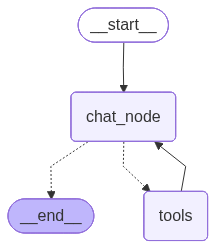

In [16]:
# Defining tools_node
tools_node = ToolNode(tools_list)

# Defining graph
graph = StateGraph(ChatState)

# Adding nodes in graph
graph.add_node('chat_node', chat_node)
graph.add_node('tools', tools_node)


# Adding edges
graph.add_edge(START, 'chat_node')
graph.add_conditional_edges('chat_node', tools_condition)
graph.add_edge('tools', 'chat_node')
graph.add_edge("chat_node", END)

# Conpiling the graph
chatbot = graph.compile(checkpointer = checkpointer)

chatbot

dict_keys(['google_search', 'weather_search', 'train_search'])

In [24]:
# Passing initial state
'''
config = {'configurable': {'thread_id': '1'}}
initial_state = {'messages': 'When train number 22959 reaches Rajkot Junction?'}

response = chatbot.invoke(initial_state, config = config)
'''

# Passing initial state

config = {'configurable': {'thread_id': '1'}}
initial_state = {'messages': 'When train number 22959 reaches Rajkot Junction?'}

response = chatbot.invoke(initial_state, config = config)

In [25]:
response['messages']
# See, there is no interruption

[HumanMessage(content='When train number 22959 reaches Rajkot Junction?', additional_kwargs={}, response_metadata={}, id='367d629d-4968-4e56-87d2-3286d88f4dca'),
 AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 16, 'prompt_tokens': 229, 'total_tokens': 245, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-3.5-turbo-0125', 'system_fingerprint': None, 'id': 'chatcmpl-CvnEHhanaRiA5L0qAJQATMhXEX2jY', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019b9e74-1a3b-7412-b72f-e4e37bffc281-0', tool_calls=[{'name': 'train_search', 'args': {'train_number': '22959'}, 'id': 'call_b52sMPhipljfCE6WVTLZS9yv', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 229, 'outp

In [26]:
response['messages'][1].tool_calls

[{'name': 'train_search',
  'args': {'train_number': '22959'},
  'id': 'call_b52sMPhipljfCE6WVTLZS9yv',
  'type': 'tool_call'}]

In [29]:
chatbot = graph.compile(
    checkpointer=checkpointer,
    middlewares=[hitl_middleware]   # <-- attach here
)


TypeError: StateGraph.compile() got an unexpected keyword argument 'middlewares'

In [28]:
# HITL Middleware
hitl_middleware = HumanInTheLoopMiddleware(
    interrupt_on = {'train_search': True}
)

# Wrap with HITL middleware
hitl_chatbot = hitl_middleware(chatbot)


TypeError: 'HumanInTheLoopMiddleware' object is not callable

In [145]:
# Taking user_input

user_input = input(f'''Backend Message: {interrupt_message['permission']}''')

Backend Message: Should I continue with calling the tool? (yes/no) yes


In [146]:
final_response = chatbot.invoke(
    Command(resume = {"decision": user_input}),
    config = config
)

In [147]:
final_response['messages'][-1].content

''

In [47]:
# continue flow

while True:
    user_input = input("Enter your question: ").strip().lower()

    if user_input in ['exit', 'break']:
        print("Thankyou! Have a nice day.")
        break

    config = {'configurable': {'thread_id': '1'}}
    initial_message = {'messages': [user_input]}

    response = chatbot.invoke(initial_message, config = config)

    # if interrupted
    if response.get('__interrupt__'):
        interrupt_message = response['__interrupt__'][0].value

        permission = input(f'''Backend message: {interrupt_message} - ''')

        cmd = Command(resume = permission)

        final_response = chatbot.invoke(cmd, config = config)

        print(final_response['messages'] [-1].content)

    else:
        print(response['messages'][-1].content)
        
        

Enter your question:  Hi


Hello! How can I help you today?


Enter your question:  My name is Nikunj. Tell me the full form of PCA in Machune Learning.


Principal Component Analysis


Enter your question:  When does train number 22960 reaches Kalupur Junction?
Backend message: Should I continue calling the train_search tool? (yes/no) -  yes


Train number 22960 reaches Kalupur Junction (Ahmedabad Jn) at 10:20.


Enter your question:  exit


# `Next:` 22 How to build sub-graphs in LangGraoh